# 02 — Estatistica Descritiva e Dispersao

**Objetivos de aprendizagem:** comparar medidas de posição e variabilidade e interpretar dados assimétricos

**Pré-requisitos:** Notebook 01

**Origem:** Slides, aulas 02–03, páginas 57–92. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia técnico: Estatistica Descritiva e Dispersao](./reference_materials/02_estatistica_descritiva_e_dispersao.pdf)
- [Cheat sheet: Estatistica Descritiva e Dispersao](./cheat_sheets/cheat_sheet_estatistica_descritiva_e_dispersao.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta disciplina usa Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. Medidas de posição

A média usa todos os valores e é sensível a extremos. A mediana identifica o centro ordenado; a moda é o valor mais frequente. A escolha depende da pergunta e do tipo de variável.

In [2]:
df=ler_dataset('candidatos_reconstruidos.csv')
x=df['idade']
print('média',x.mean(),'mediana',x.median(),'moda',x.mode().to_list())
print('quantis',x.quantile([.25,.5,.75]).to_dict())

média 20.95 mediana 21.0 moda [19, 21]
quantis {0.25: 19.0, 0.5: 21.0, 0.75: 22.25}


In [3]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'estatistica':['n','media','mediana','desvio_amostral','q1','q3','minimo','maximo'], 'valor':[x.count(),x.mean(),x.median(),x.std(ddof=1),x.quantile(.25),x.quantile(.75),x.min(),x.max()]}).to_csv(OUTPUTS / '02_resumo_idades.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 2. Variância amostral vs populacional

A variância populacional divide a soma dos desvios quadráticos por `N`; a variância amostral usual, estimadora não viesada da variância sob amostragem i.i.d., divide por `n−1`. O desvio padrão é sua raiz e tem as unidades originais.

In [4]:
m=x.mean();soma=((x-m)**2).sum()
var_pop=soma/len(x);var_amostra=soma/(len(x)-1)
print('Soma dos quadrados',soma,'variância pop',var_pop,'variância amostral',var_amostra)
assert np.isclose(var_amostra,x.var(ddof=1))
assert np.isclose(np.sqrt(var_amostra),x.std(ddof=1))

Soma dos quadrados 100.94999999999999 variância pop 5.047499999999999 variância amostral 5.313157894736841


## 3. IQR, boxplot e assimetria

O intervalo interquartil é `Q3−Q1`. Limites convencionais `Q1−1,5×IQR` e `Q3+1,5×IQR` sinalizam *potenciais* valores atípicos; não são critérios universais para exclusão.

IQR 3.25 limites 14.125 27.125


/tmp/ipykernel_26829/1532025130.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  fig,axs=plt.subplots(1,2,figsize=(9,3));axs[0].hist(x,bins=range(17,28),edgecolor='black');axs[1].boxplot(x,vert=False);axs[0].set_title('Histograma');axs[1].set_title('Boxplot');plt.tight_layout();fig.savefig(OUTPUTS / '02_histograma_boxplot_idades.png', dpi=160, bbox_inches='tight');plt.show()


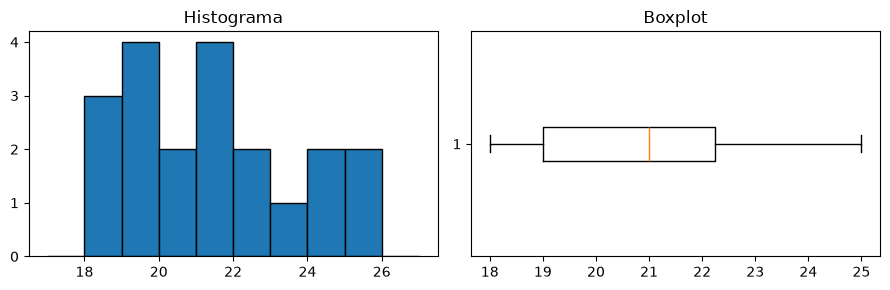

In [5]:
q1,q3=x.quantile([.25,.75]);iqr=q3-q1
print('IQR',iqr,'limites',q1-1.5*iqr,q3+1.5*iqr)
fig,axs=plt.subplots(1,2,figsize=(9,3));axs[0].hist(x,bins=range(17,28),edgecolor='black');axs[1].boxplot(x,vert=False);axs[0].set_title('Histograma');axs[1].set_title('Boxplot');plt.tight_layout();fig.savefig(OUTPUTS / '02_histograma_boxplot_idades.png', dpi=160, bbox_inches='tight');plt.show()

## 4. Sensibilidade a extremos — demonstração sintética

Um valor extremo pode deslocar muito a média, enquanto a mediana costuma ser mais estável. Este experimento é artificial e ilustra robustez, não identifica erro nos dados originais.

In [6]:
a=np.array([10,11,12,13,14]);b_ext=np.array([10,11,12,13,100])
print(pd.DataFrame({'sem_extremo':[a.mean(),np.median(a)],'com_extremo':[b_ext.mean(),np.median(b_ext)]},index=['Média','Mediana']))

         sem_extremo  com_extremo
Média           12.0         29.2
Mediana         12.0         12.0


## 5. Dados de desocupação — aplicação com ressalvas

O CSV histórico recuperado não apresenta fonte, ano ou descrição metodológica suficiente. Usaremos apenas sua estrutura para exercícios; **não** trataremos as taxas como indicadores atuais ou comparáveis entre períodos.

In [7]:
taxas=ler_dataset('tx_desocupacao_estados_br.csv')
display(taxas.head());print(taxas['Taxa_desocupacao'].describe().round(2))
print('coeficiente de variação (%)',round(100*taxas['Taxa_desocupacao'].std()/taxas['Taxa_desocupacao'].mean(),2))

,Estado,Sigla,Taxa_desocupacao
0,Acre,AC,14.2
1,Alagoas,AL,17.8
2,Amapá,AP,11.4
3,Amazonas,AM,16.5
4,Bahia,BA,19.9


count    27.00
mean     13.44
std       3.22
min       6.90
25%      11.40
50%      12.80
75%      15.80
max      19.90
Name: Taxa_desocupacao, dtype: float64
coeficiente de variação (%) 23.94


In [8]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
taxas['Taxa_desocupacao'].describe().rename('valor').to_csv(OUTPUTS / '02_resumo_taxas_desocupacao.csv', encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


### Exercício resolvido — Conferir os quartis e a contagem

**Solução comentada:**

In [9]:
assert (x.min(),x.max())==(18,25)
print('mínimo, máximo, amplitude:',x.min(),x.max(),x.max()-x.min())

mínimo, máximo, amplitude: 18 25 7


**Interpretação:** A amplitude reflete apenas extremos; para comparar dispersão, use também desvio padrão e IQR.

### Exercício resolvido — Variância sob reescala

**Solução comentada:**

In [10]:
y=2*x+5
print(x.var(),y.var());assert np.isclose(y.var(),4*x.var())

5.313157894736841 21.252631578947366


**Interpretação:** Multiplicar todos os dados por 2 multiplica o desvio padrão por 2, mas a variância por 4.

## Erros comuns e limites

Não confunda variância e desvio padrão nem apresente um boxplot como prova automática de anomalia. `ddof=0` e `ddof=1` respondem a convenções diferentes.

## Consulta Rápida

`s.mean()` · `s.median()` · `s.mode()` · `s.quantile([.25,.75])` · `s.var(ddof=1)` · `s.std(ddof=1)` · `ax.boxplot(s)`.

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Estimadores robustos e intervalos interquartis

Média e desvio padrão descrevem posição e dispersão, mas são sensíveis a caudas e valores extremos. Mediana e MAD (median absolute deviation, com constante de normalização quando apropriado) oferecem alternativas robustas. A regra de 1,5×IQR é **heurística de exploração**, não prova de erro ou fraude.

In [11]:
from scipy import stats
amostra_limpa = np.array([10., 11., 12., 13., 14.])
amostra_extremo = np.r_[amostra_limpa[:-1], 100.]
comparacao_robusta = pd.DataFrame({
    'medida': ['media', 'mediana', 'desvio_padrao_amostral', 'MAD_normalizado'],
    'sem_extremo': [amostra_limpa.mean(), np.median(amostra_limpa), amostra_limpa.std(ddof=1), stats.median_abs_deviation(amostra_limpa, scale='normal')],
    'com_extremo': [amostra_extremo.mean(), np.median(amostra_extremo), amostra_extremo.std(ddof=1), stats.median_abs_deviation(amostra_extremo, scale='normal')]
})
display(comparacao_robusta.round(3))
assert abs(np.median(amostra_extremo) - np.median(amostra_limpa)) < abs(amostra_extremo.mean() - amostra_limpa.mean())

,medida,sem_extremo,com_extremo
0,media,12.000,29.200
1,mediana,12.000,12.000
2,desvio_padrao_amostral,1.581,39.594
3,MAD_normalizado,1.483,1.483


### Exercício resolvido

**Pergunta:** por que uma média muito maior que a mediana não deve automaticamente ser removida da análise?

**Solução:** a diferença pode revelar assimetria legítima. Investigue coleta, domínio, unidade de medida e distribuição antes de qualquer exclusão. Reporte estimativas robustas e não robustas quando houver razões substantivas.